# auto_annot_Haber2017_with_Smillie2019_dblabel_level2

In [1]:
import besca as bc
import scanpy as sc
import pandas as pd
from importlib.resources import files as _resource_files
import os

### Specify folders where .h5ad files are found and their names. 

The datasets that are already annotated and should be used for training. If you only use one dataset please use list of one.

In [2]:
adata_trains = [bc.datasets.Smillie2019_processed()]

The dataset of interest that should be annotated.

In [3]:
adata_pred = bc.datasets.Haber2017_processed()
adata_orig = bc.datasets.Haber2017_processed()

Define level of dblabel reference annotation

In [4]:
level = 2

Give your analysis a name.

In [5]:
analysis_name = 'auto_annot_Haber2017_with_Smillie2019_dblabel_l' + str(level) 

### Now specify parameters

Specify column name of celltype annotation you want to train on.

In [6]:
celltype_train ='dblabel_l' + str(level)
celltype_test = 'dblabel_l' + str(level)

Choose a method:

- linear: Support Vector Machine with Linear Kernel
- sgd: Support Vector Machine with Linear Kernel using Stochastic Gradient Descent
- rbf: Support Vector Machine with radial basis function kernel. Very time intensive, use only on small datasets.
- logistic_regression: Standard logistic classifier iwth multinomial loss.
- logistic_regression_ovr: Logistic Regression with one versus rest classification.
- logistic_regression_elastic: Logistic Regression with elastic loss, cross validates among multiple l1 ratios.

In [7]:
method = 'logistic_regression_elastic' # 'logistic_regression'

Specify merge method if using multiple training datasets. Needs to be either scanorama or naive.

In [8]:
merge = 'scanorama'

Decide if you want to use the raw format or highly variable genes. Raw increases computational time and does not necessarily improve predictions.

In [9]:
use_raw = False

You can choose to only consider a subset of genes from a signature set.

In [10]:
genes_to_use = 'all'

### Translate cell type annoation to lower dblabel level

In [11]:
new_cnames = bc.tl.sig.obtain_new_label(
    nomenclature_file=str(_resource_files('besca').joinpath('datasets').joinpath('nomenclature').joinpath('CellTypes_v1.tsv')), 
    cnames=list(adata_trains[0].obs['dblabel'].cat.categories), 
    reference_label='dblabel', 
    new_label='dblabel', 
    new_level=level)

new_cnames

,new_label
CD1c-positive myeloid dendritic cell,myeloid leukocyte
"CD4-positive, alpha-beta memory T cell",lymphocyte
"CD8-positive, alpha-beta T cell",lymphocyte
"CD8-positive, alpha-beta cytokine secreting effector T cell",lymphocyte
CD141-positive myeloid dendritic cell,myeloid leukocyte
HEV endothelial cell,endothelial cell of vascular tree
"activated CD4-positive, alpha-beta T cell",lymphocyte
brush cell,endo-epithelial cell
endothelial cell,endothelial cell
enterocyte,endo-epithelial cell


In [12]:
adata_trains[0].obs['dblabel_l' + str(level)] = bc.tl.sig.add_anno(adata_trains[0], new_cnames, 'new_label', 'dblabel')

In [13]:
new_cnames = bc.tl.sig.obtain_new_label(
    nomenclature_file=str(_resource_files('besca').joinpath('datasets').joinpath('nomenclature').joinpath('CellTypes_v1.tsv')), 
    cnames=list(adata_pred.obs['dblabel'].cat.categories), 
    reference_label='dblabel', 
    new_label='dblabel', 
    new_level=level)

new_cnames

,new_label
goblet cell,glandular epithelial cell
proliferating epithelial fate stem cell,stem cell
enterocyte,endo-epithelial cell
epithelial fate stem cell,stem cell
immature goblet cell,glandular epithelial cell
brush cell,endo-epithelial cell
proliferating transit amplifying cell,endo-epithelial cell
paneth cell,endo-epithelial cell
transit amplifying cell,endo-epithelial cell
proliferating enterocyte progenitor,endo-epithelial cell


In [14]:
adata_pred.obs['dblabel_l' + str(level)] = bc.tl.sig.add_anno(adata_pred, new_cnames, 'new_label', 'dblabel')
adata_orig.obs['dblabel_l' + str(level)] = adata_pred.obs['dblabel_l' + str(level)] 

### Prepare all training and the testing set.

In [15]:
# Select epithelial subset from Smillie2019 dataset
epithelial_subset = bc.subset_adata(adata_trains[0], adata_trains[0].obs.celltype_highlevel == 'Epi', raw=False)
adata_trains[0] = epithelial_subset

In [16]:
# Convert mouse symbols (MGI) to human symbols (HGNC)
mousehuman_file = str(_resource_files('besca').joinpath('datasets').joinpath('homologs').joinpath('MGItoHGNC.csv'))
mousehuman=pd.read_csv(mousehuman_file,sep='\t',header='infer', encoding="unicode_escape")
mousehuman.index=mousehuman['MGI']
conversion=pd.Series(data=mousehuman['HGNC'], index=mousehuman.index)

In [17]:
# Convert mouse symbols (MGI) to human symbols (HGNC)
adata_orig.var.rename(columns={'SYMBOL':'MGI'}, inplace=True)
adata_orig.var['SYMBOL'] = adata_orig.var['MGI'].map(lambda x: conversion.get(x, default='') if type(conversion.get(x, default='')) == str else conversion.get(x, default=None).values[0])
adata_orig.var.index = adata_orig.var.SYMBOL
adata_orig.var_names_make_unique()
adata_pred = adata_orig.copy()

This function merges training datasets, removes unwanted genes, and if scanorama is used corrects for datasets.

In [18]:
adata_train, adata_pred = bc.tl.auto_annot.merge_data(adata_trains, adata_pred, genes_to_use = genes_to_use, merge = merge)

merging with scanorama
using scanorama rn
Found 278 genes among all datasets
[[0.         0.75137665]
 [0.         0.        ]]
Processing datasets (0, 1)
integrating training set
calculating intersection


### Train the classifier.

The returned scaler is fitted on the training dataset (to zero mean and scaled to unit variance).

In [19]:
classifier, scaler = bc.tl.auto_annot.fit(adata_train, method, celltype_train)

[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.


convergence after 14 epochs took 5 seconds
convergence after 14 epochs took 5 seconds
convergence after 15 epochs took 6 seconds
convergence after 30 epochs took 11 seconds
max_iter reached after 37 seconds
max_iter reached after 36 seconds
max_iter reached after 39 seconds
max_iter reached after 38 seconds
max_iter reached after 38 seconds
max_iter reached after 37 seconds
max_iter reached after 37 seconds
max_iter reached after 37 seconds
max_iter reached after 37 seconds
max_iter reached after 37 seconds
max_iter reached after 37 seconds
max_iter reached after 38 seconds
max_iter reached after 37 seconds
max_iter reached after 38 seconds
max_iter reached after 39 seconds
max_iter reached after 38 seconds
max_iter reached after 39 seconds
max_iter reached after 39 seconds
max_iter reached after 38 seconds
max_iter reached after 38 seconds
max_iter reached after 38 seconds
max_iter reached after 38 seconds
max_iter reached after 39 seconds
max_iter reached after 39 seconds
max_iter re

[Parallel(n_jobs=10)]: Done   3 out of   3 | elapsed:  5.8min finished


### Prediction

Use fitted model to predict celltypes in adata_pred. Prediction will be added in a new column called 'auto_annot'. Paths are needed as adata_pred will revert to its original state (all genes, no additional corrections).
The threshold should be set to 0 or left out for SVM. For logisitic regression the threshold can be set.

In [20]:
adata_predicted = bc.tl.auto_annot.adata_predict(classifier = classifier, scaler = scaler, adata_pred = adata_pred, adata_orig = adata_orig, threshold = 0)

Write out metrics to a report file, create confusion matrices and comparative umap plots

In [21]:
adata_pred.obs

,CELL,CONDITION,sample_type,donor,region_x,sample,percent_mito,n_counts,n_genes,batch,...,celltype0,celltype1,celltype2,celltype3,dblabel,barcode,region_y,cell_label,_merge,dblabel_l2
0,haber_intestine_donor_M1_Duo.AAACATACAGCGGA,healthy,mouse_small_intestine_epithelial,M1,Duo,Duo_M1,0.001410,12768.0,1227,Duo,...,epithelial cell,paneth cell,paneth cell,paneth cell,paneth cell,AAACATACAGCGGA,Jejunum,Paneth,both,endo-epithelial cell
1,haber_intestine_donor_M1_Duo.AAACATACCTTACT,healthy,mouse_small_intestine_epithelial,M1,Duo,Duo_M1,0.010779,6583.0,2156,Duo,...,epithelial cell,enterocyte,enterocyte,enterocyte,enterocyte,AAACATACCTTACT,Jejunum,Enterocyte,both,endo-epithelial cell
2,haber_intestine_donor_M1_Duo.AAACCGTGCAGTCA,healthy,mouse_small_intestine_epithelial,M1,Duo,Duo_M1,0.022508,2799.0,1362,Duo,...,epithelial cell,epithelial fate stem cell,proliferating epithelial fate stem cell,proliferating epithelial fate stem cell,proliferating epithelial fate stem cell,AAACCGTGCAGTCA,Jejunum,TA,both,stem cell
3,haber_intestine_donor_M1_Duo.AAACGCTGCAGTCA,healthy,mouse_small_intestine_epithelial,M1,Duo,Duo_M1,0.015041,6048.0,2287,Duo,...,epithelial cell,transit amplifying cell,transit amplifying cell,transit amplifying cell,transit amplifying cell,AAACGCTGCAGTCA,Jejunum,TA,both,endo-epithelial cell
4,haber_intestine_donor_M1_Duo.AAACGCTGCGTGAT,healthy,mouse_small_intestine_epithelial,M1,Duo,Duo_M1,0.023022,2780.0,1320,Duo,...,epithelial cell,transit amplifying cell,transit amplifying cell,transit amplifying cell,transit amplifying cell,AAACGCTGCGTGAT,Jejunum,Stem,both,endo-epithelial cell
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10891,haber_intestine_donor_M2_Il.TTTCAGTGACCAGT,healthy,mouse_small_intestine_epithelial,M2,Il,Il_M2,0.008591,5468.0,2037,Il,...,epithelial cell,transit amplifying cell,transit amplifying cell,transit amplifying cell,transit amplifying cell,TTTCAGTGACCAGT,Ileum,EP,both,endo-epithelial cell
10892,haber_intestine_donor_M2_Il.TTTCGAACAGAACA,healthy,mouse_small_intestine_epithelial,M2,Il,Il_M2,0.007760,10174.0,2884,Il,...,epithelial cell,immature enterocyte,immature enterocyte,immature enterocyte,immature enterocyte,TTTCGAACAGAACA,Ileum,Enterocyte,both,endo-epithelial cell
10893,haber_intestine_donor_M2_Il.TTTCTACTGCTCCT,healthy,mouse_small_intestine_epithelial,M2,Il,Il_M2,0.006121,9307.0,2856,Il,...,epithelial cell,immature goblet cell,immature goblet cell,immature goblet cell,immature goblet cell,TTTCTACTGCTCCT,Ileum,Goblet,both,glandular epithelial cell
10894,haber_intestine_donor_M2_Il.TTTGACTGCGCCTT,healthy,mouse_small_intestine_epithelial,M2,Il,Il_M2,0.007189,4029.0,1277,Il,...,epithelial cell,goblet cell,goblet cell,goblet cell,goblet cell,TTTGACTGCGCCTT,Ileum,Goblet,both,glandular epithelial cell


acc: 0.66
f1: 0.63


... storing 'auto_annot' as categorical
... storing 'SYMBOL' as categorical


ami: 0.27
ari: 0.23
silhouette dblabel_l2: 0.19
silhouette auto_annot: 0.04
pair confusion matrix:
          0         1
0  36142968  35836570
1  11912352  34820030


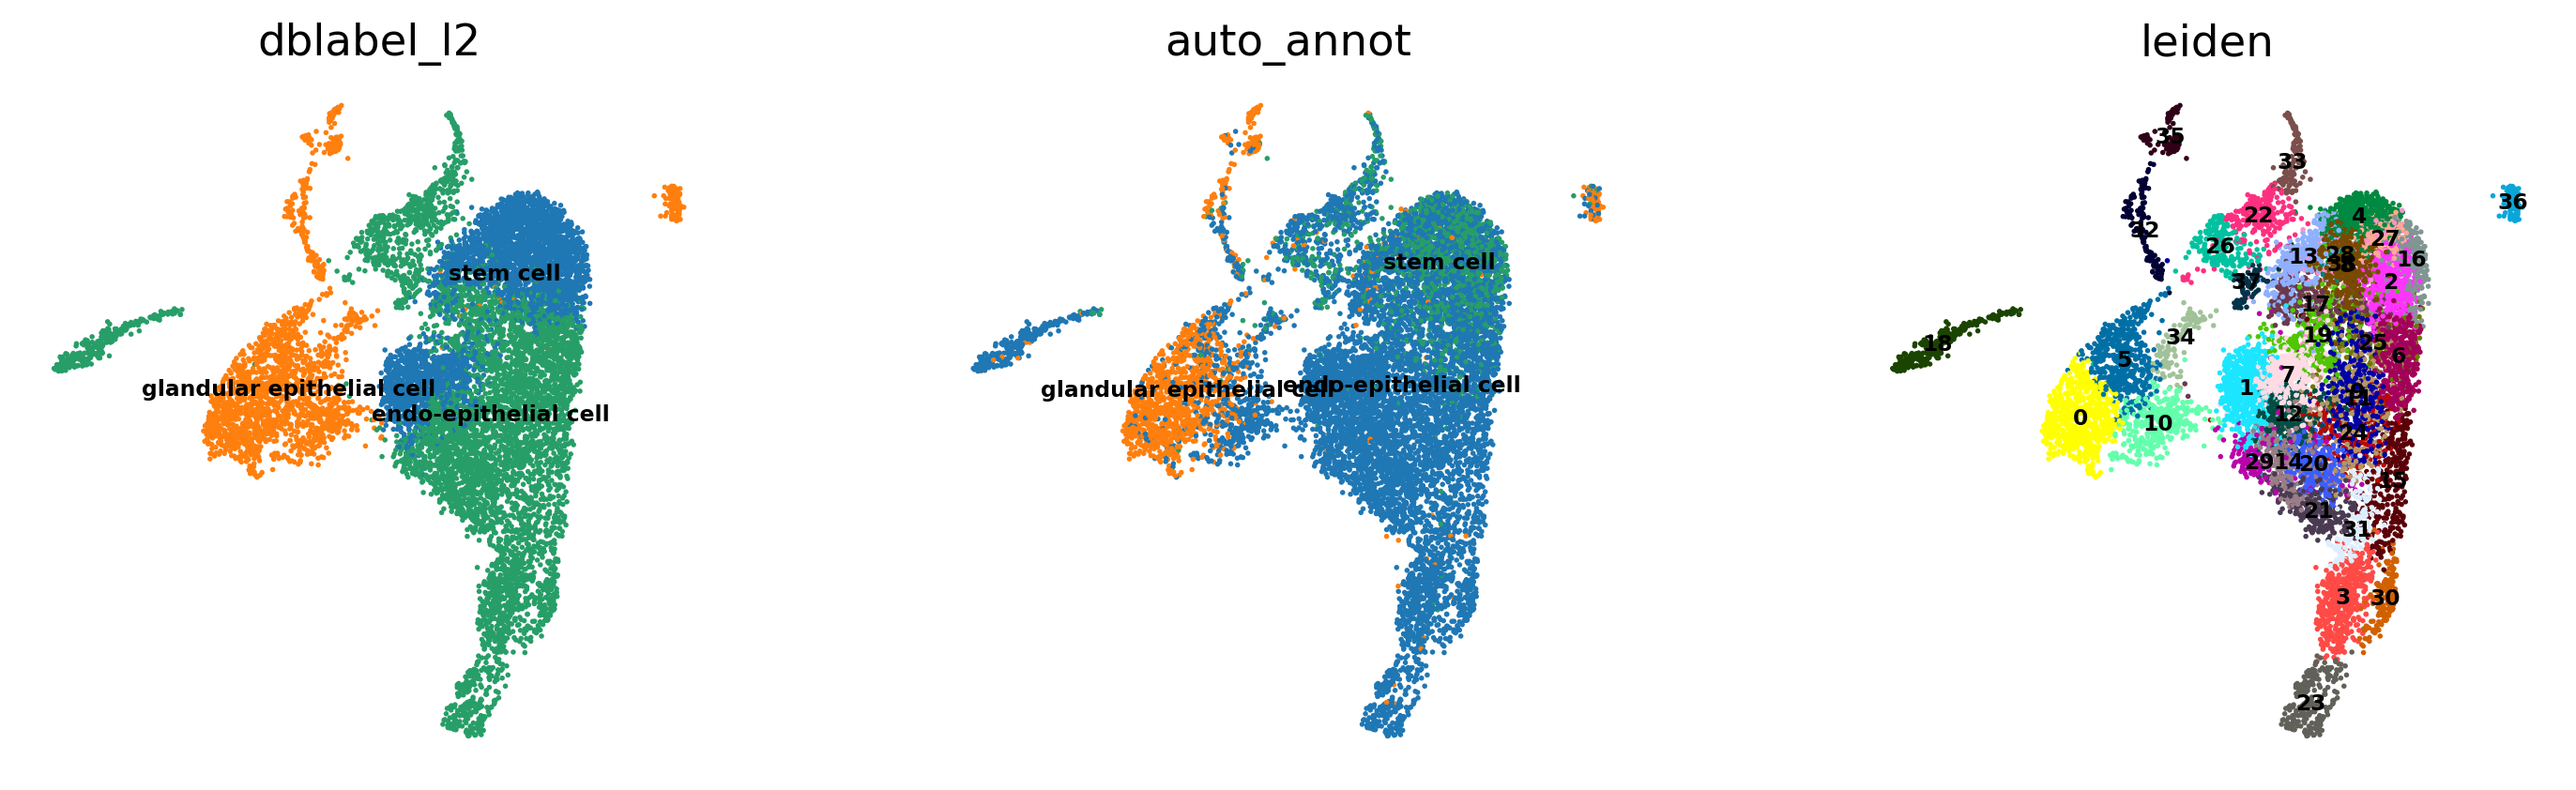

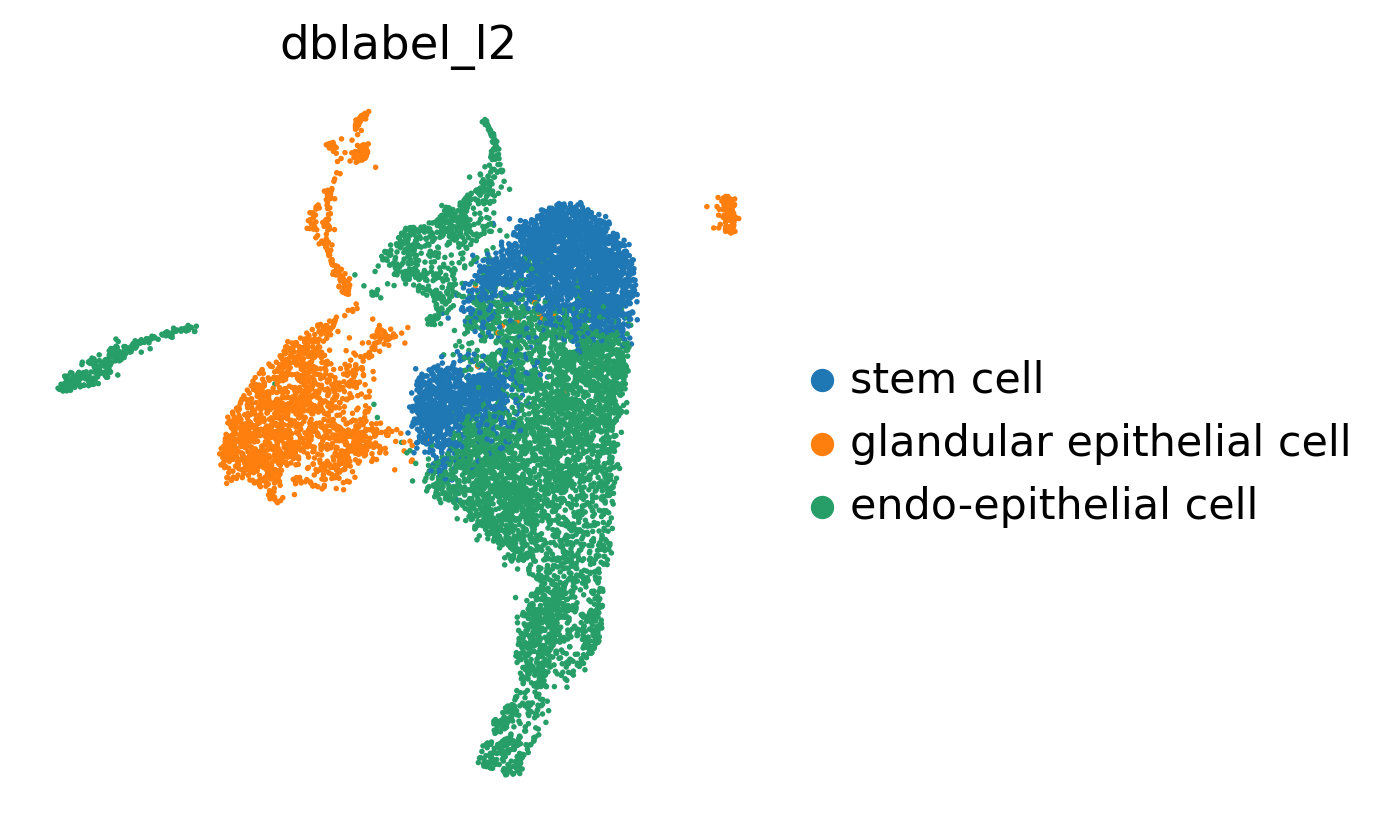

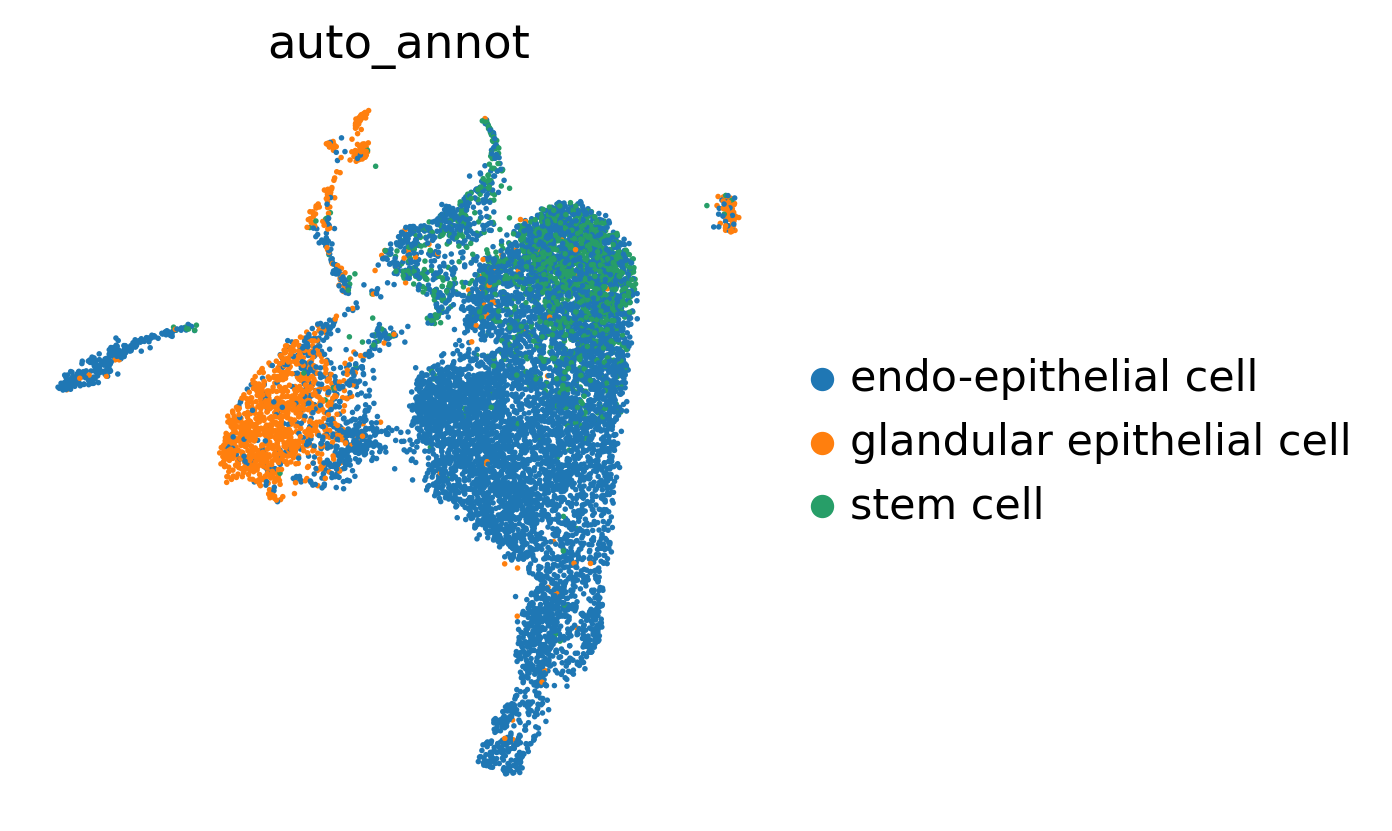

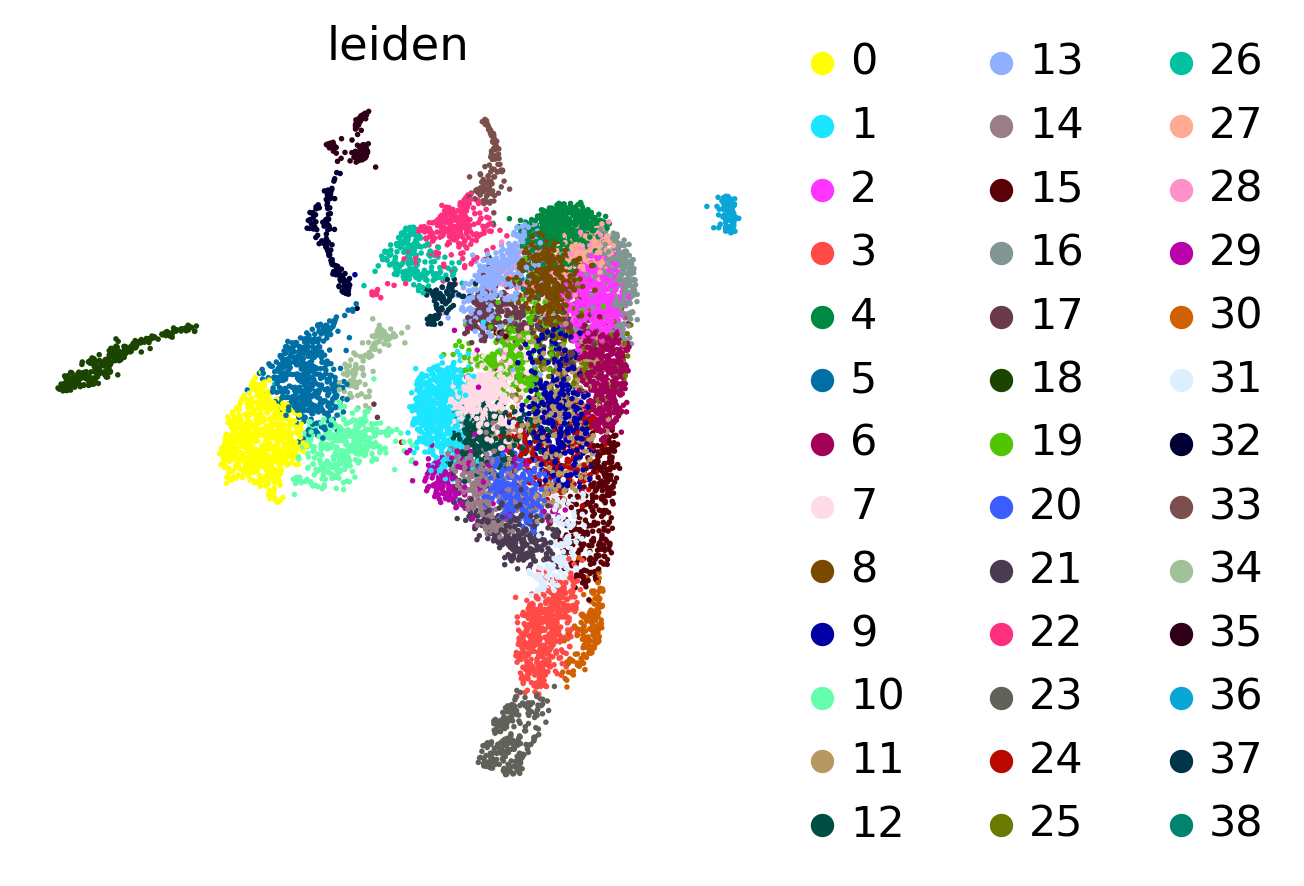

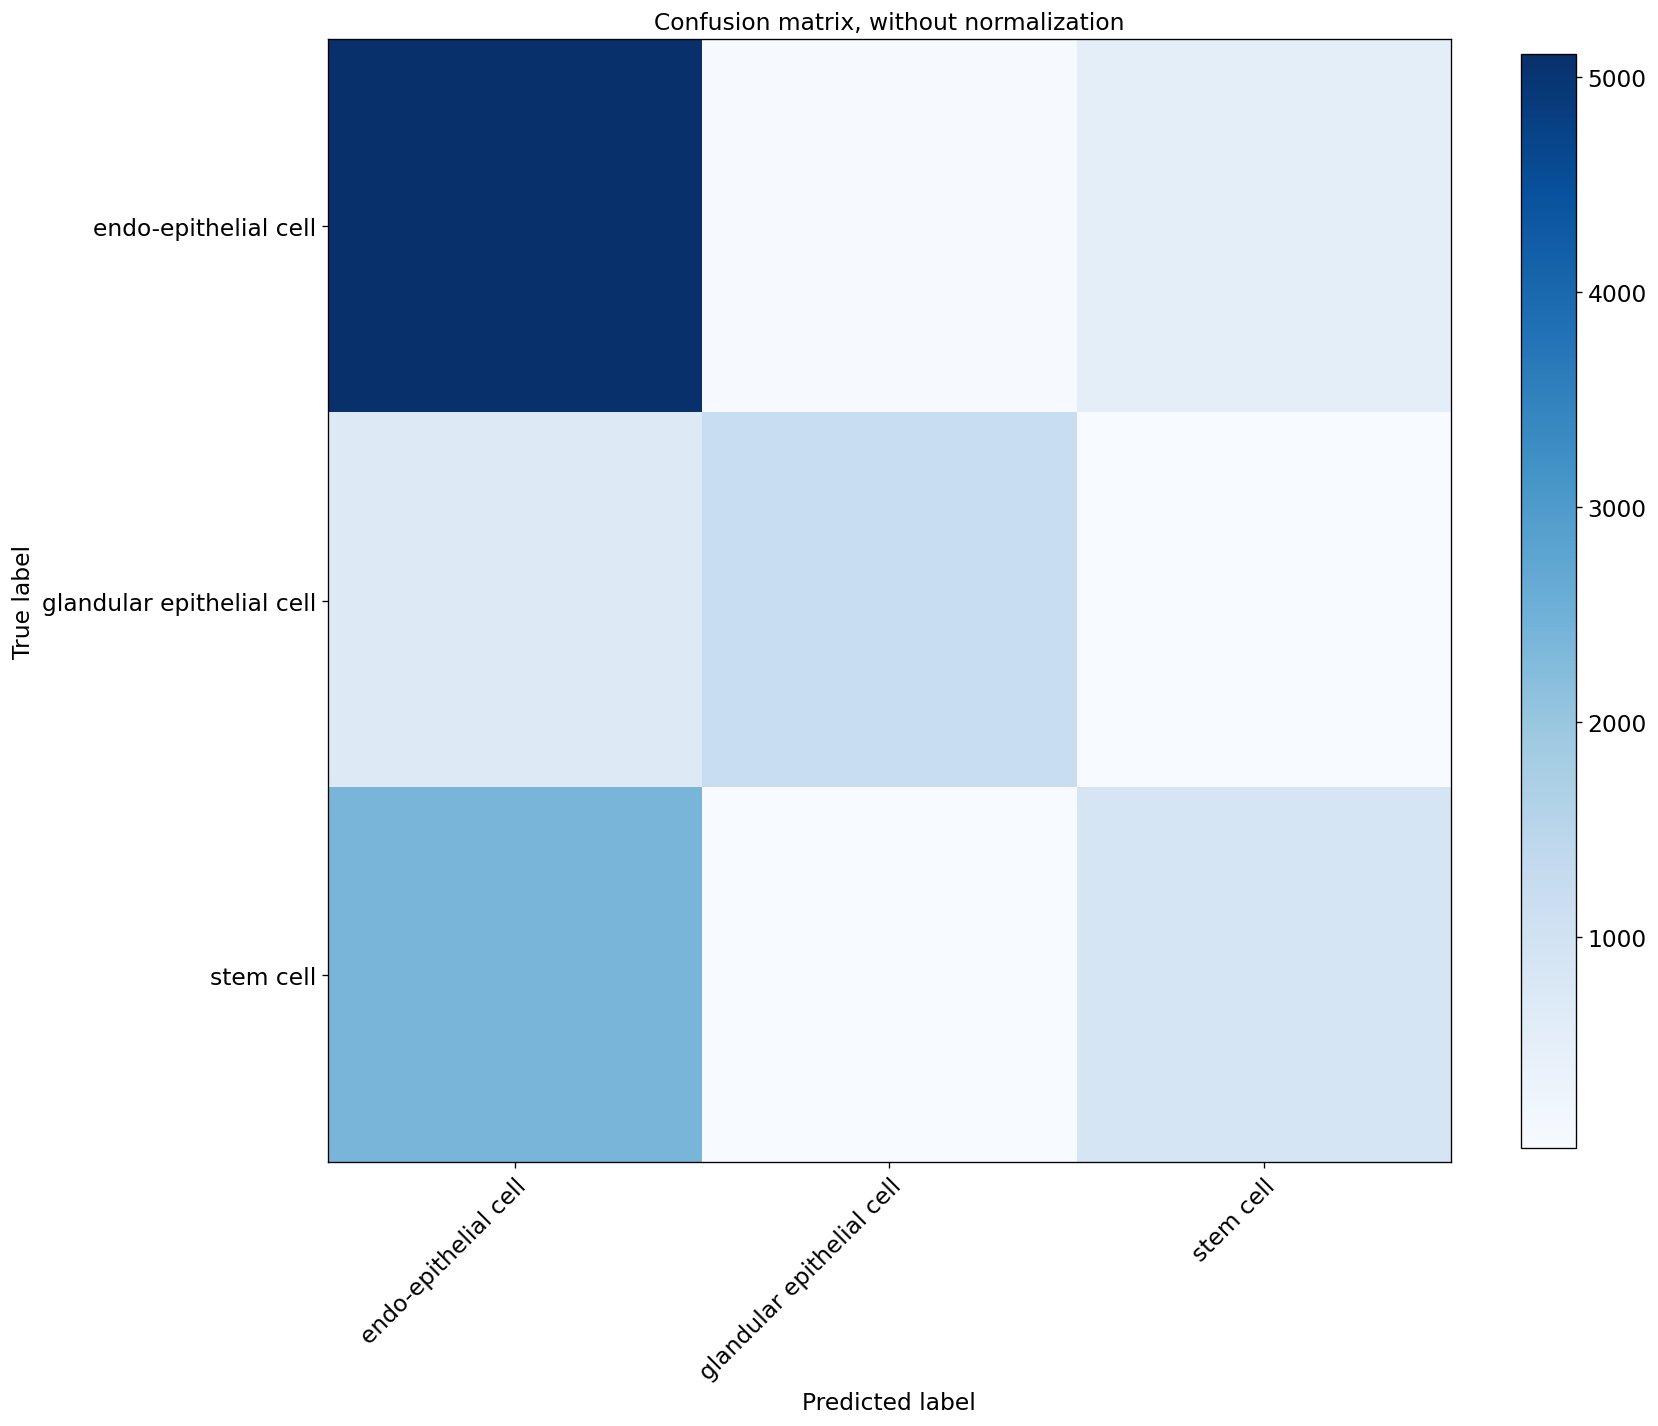

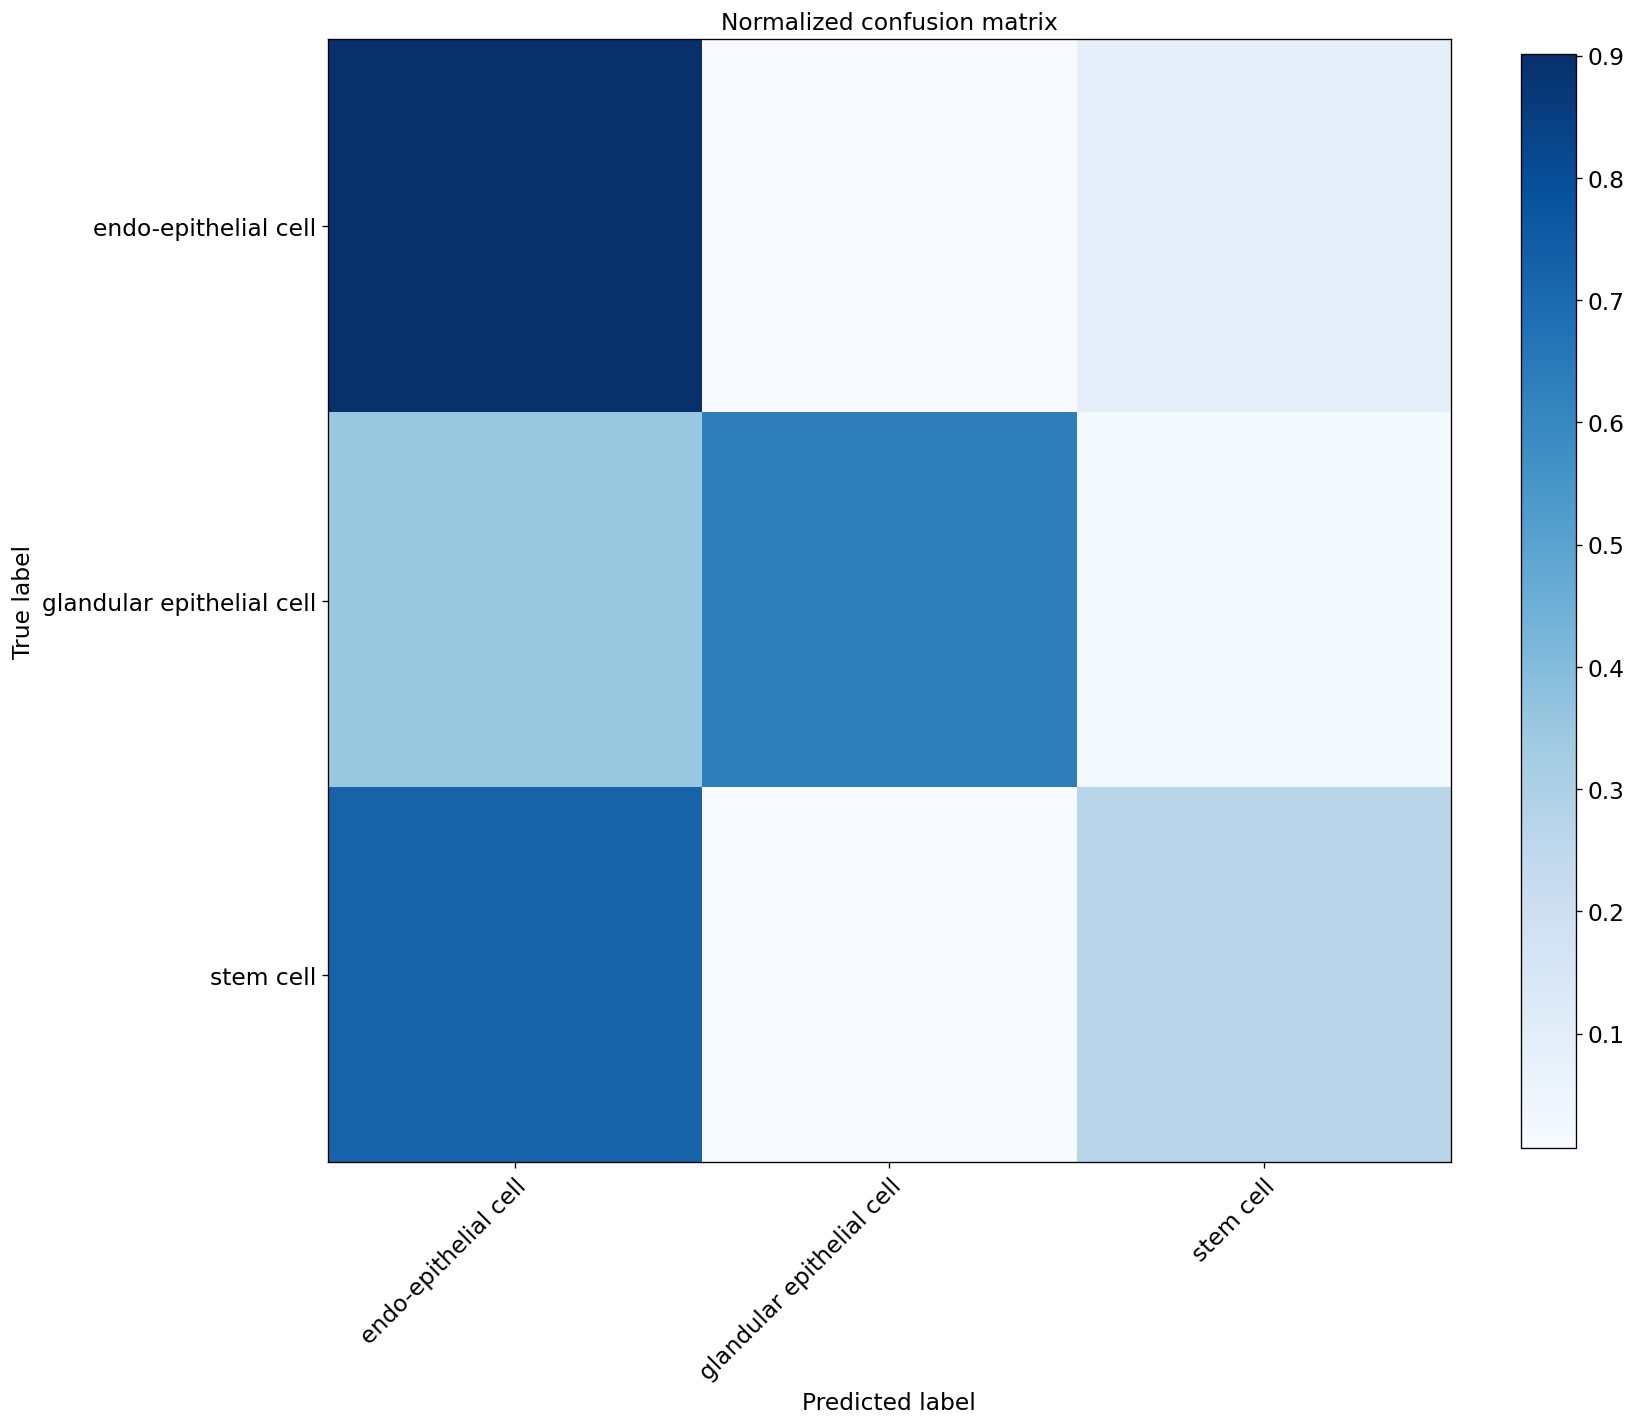

In [22]:
%matplotlib inline

bc.tl.report(
    adata_pred=adata_predicted,
    celltype=celltype_test, 
    method=method, 
    analysis_name=analysis_name,
    train_datasets = adata_trains,
    test_dataset = adata_orig,
    merge = merge,
    name_prediction='auto_annot', 
    name_report='auto_annot', 
    use_raw=use_raw,
    remove_nonshared=True, 
    clustering='leiden', 
    asymmetric_matrix=True, 
    delimiter='\t', 
    verbose=True
)

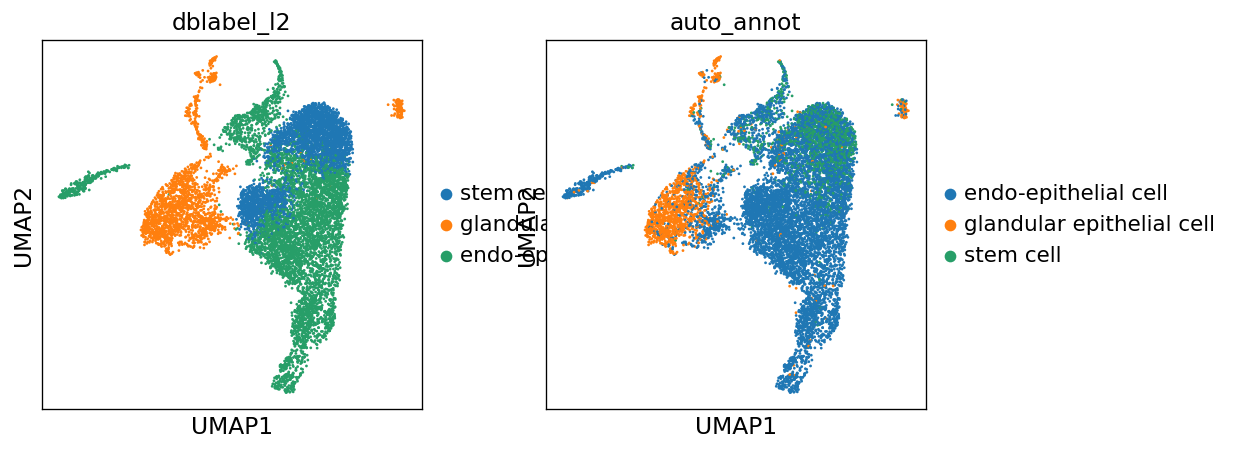

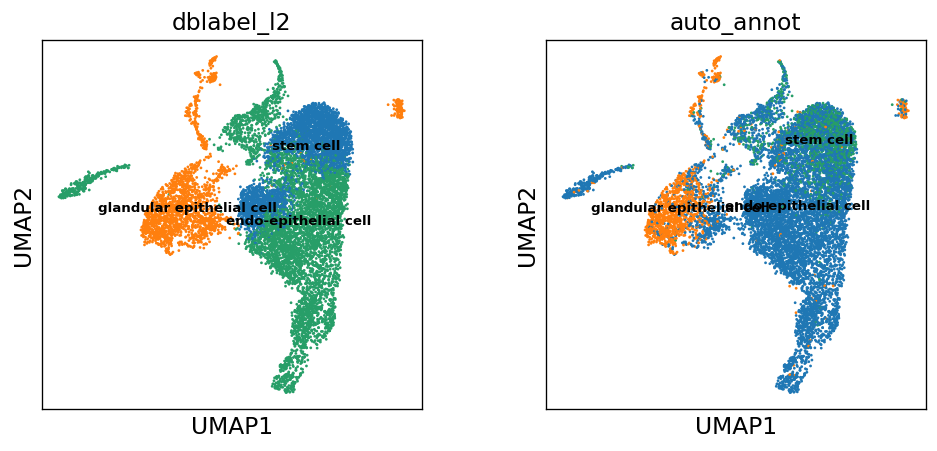

In [23]:
sc.pl.umap(adata_predicted, color=[celltype_test, 'auto_annot'])
sc.pl.umap(adata_predicted, color=[celltype_test, 'auto_annot'], legend_loc='on data', legend_fontsize=8)

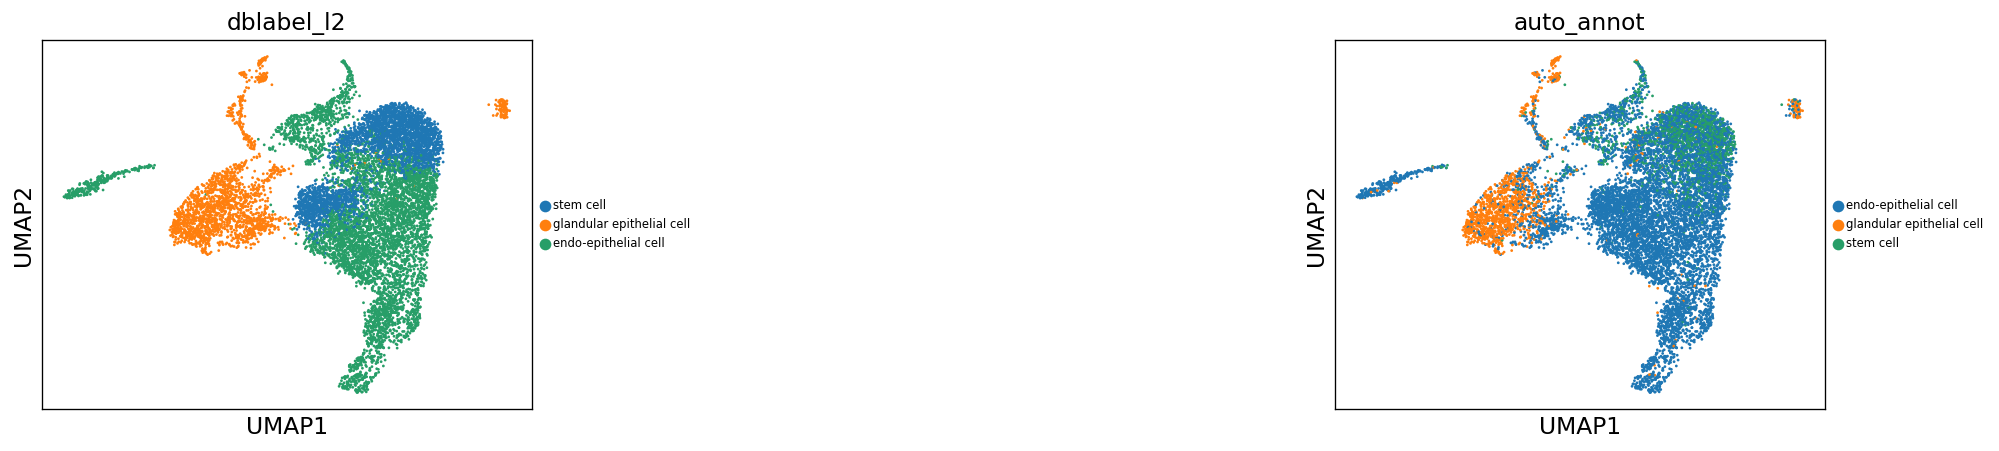

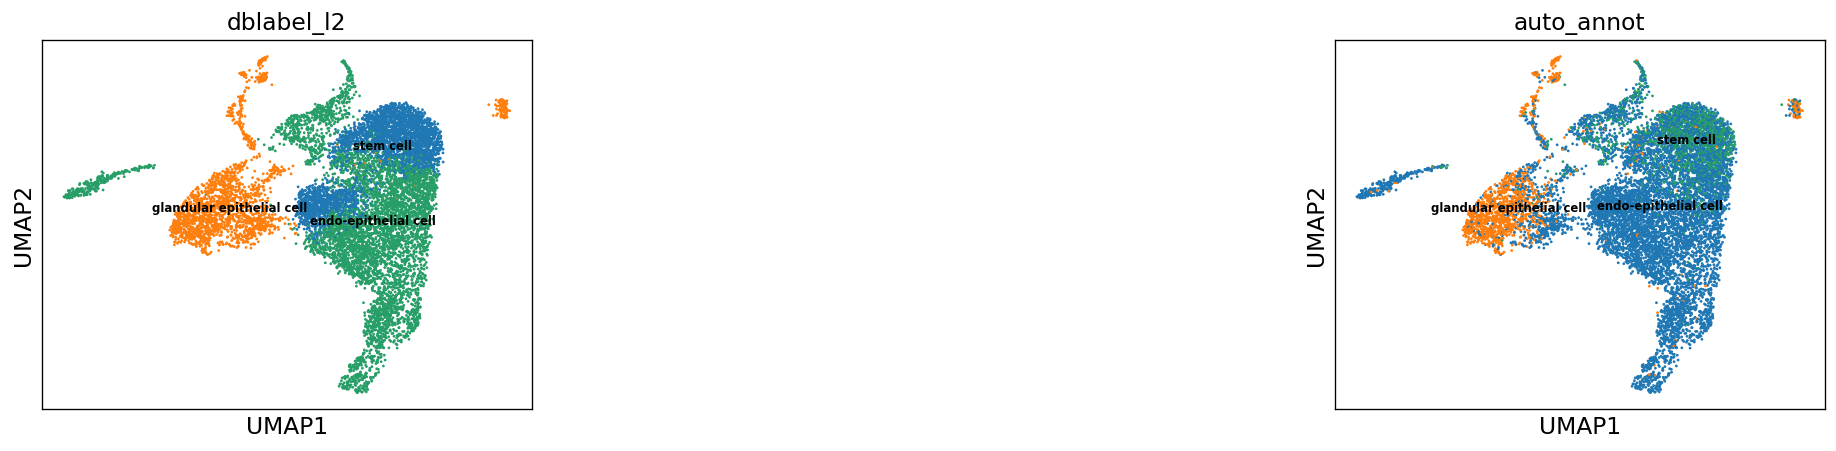

In [24]:
sc.pl.umap(adata_predicted, color=[celltype_test, 'auto_annot'], legend_fontsize=7, wspace = 1.4, save = '.svg')
sc.pl.umap(adata_predicted, color=[celltype_test, 'auto_annot'], legend_loc='on data', legend_fontsize=7, wspace = 1.4, save = '.ondata.svg')

In [25]:
adata_train

View of AnnData object with n_obs × n_vars = 46102 × 278
    obs: 'CELL', 'Cluster', 'Health', 'Location', 'Subject', 'celltype_highlevel', 'nGene', 'nUMI', 'original_name', 'percent_mito', 'n_counts', 'n_genes', 'batch', 'leiden', 'dblabel', 'celltype', 'cluster_celltype', 'Type', 'dblabel_l2'
    var: 'SYMBOL', 'ENSEMBL-0', 'n_cells-0', 'total_counts-0', 'frac_reads-0', 'ENSEMBL-1', 'n_cells-1', 'total_counts-1', 'frac_reads-1', 'MGI-1', 'highly_variable-1', 'means-1', 'dispersions-1', 'dispersions_norm-1', 'mean-1', 'std-1'
    uns: 'Cluster_colors', 'Location_colors', 'Type_colors', 'celltype_highlevel_colors', 'leiden', 'leiden_colors', 'umap'
    obsm: 'X_pca', 'X_umap', 'X_scanorama'

In [26]:
adata_predicted_wo_unknown = adata_predicted.copy()
adata_predicted_wo_unknown = bc.subset_adata(adata_predicted_wo_unknown, adata_predicted_wo_unknown.obs.auto_annot != 'unknown', raw=False)
bc.pl.riverplot_2categories(adata_predicted_wo_unknown, [celltype_test, 'auto_annot'])

acc: 0.4
f1: 0.4


... storing 'random_labeling' as categorical


ami: 0.0
ari: 0.0
silhouette dblabel_l2: 0.19
silhouette random_labeling: -0.01
pair confusion matrix:
          0         1
0  43761844  28217694
1  28217694  18514688


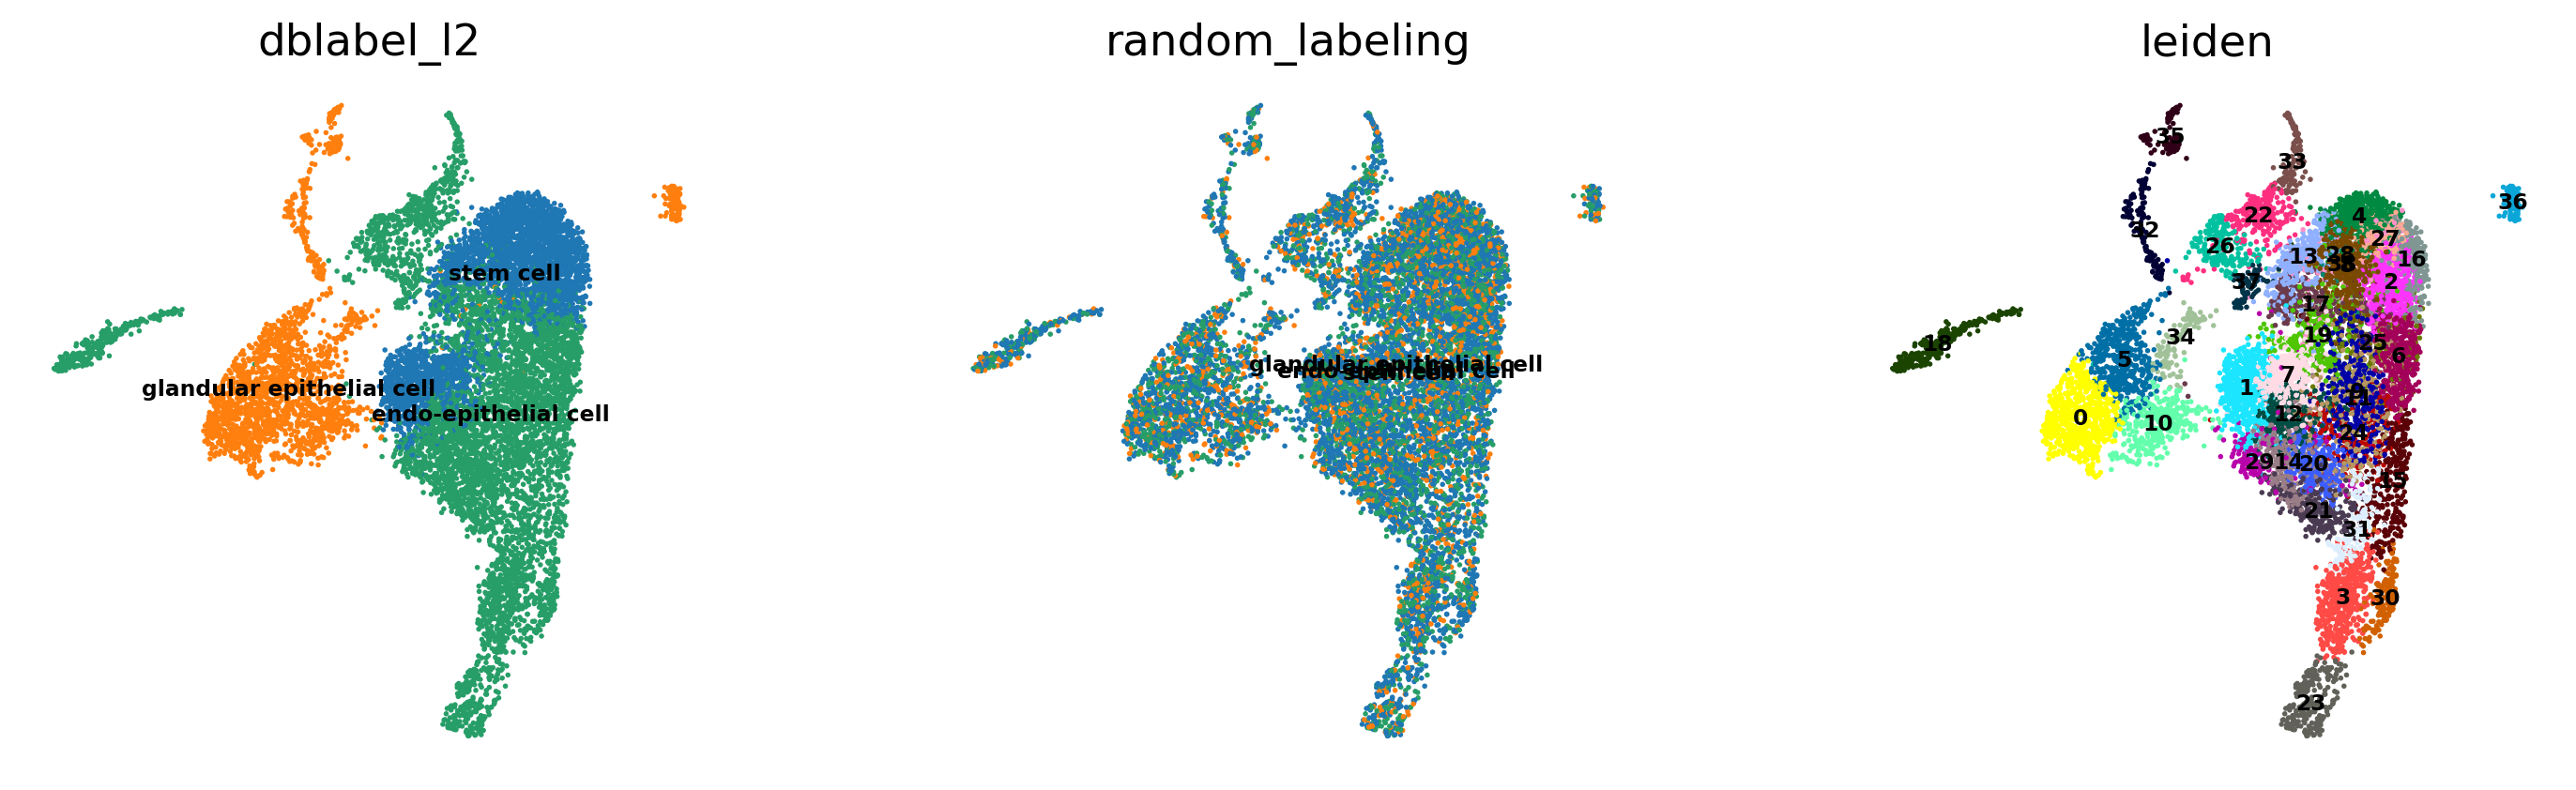

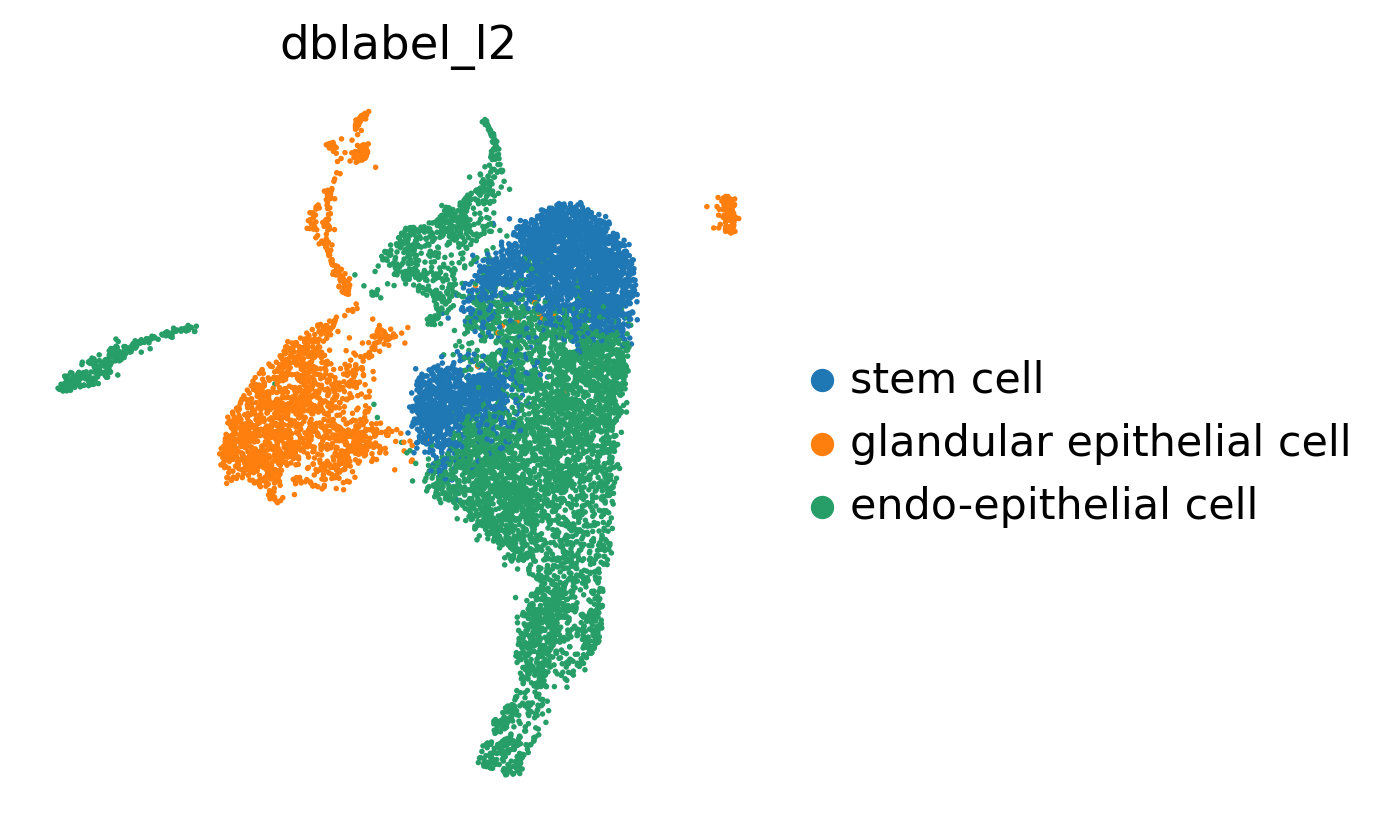

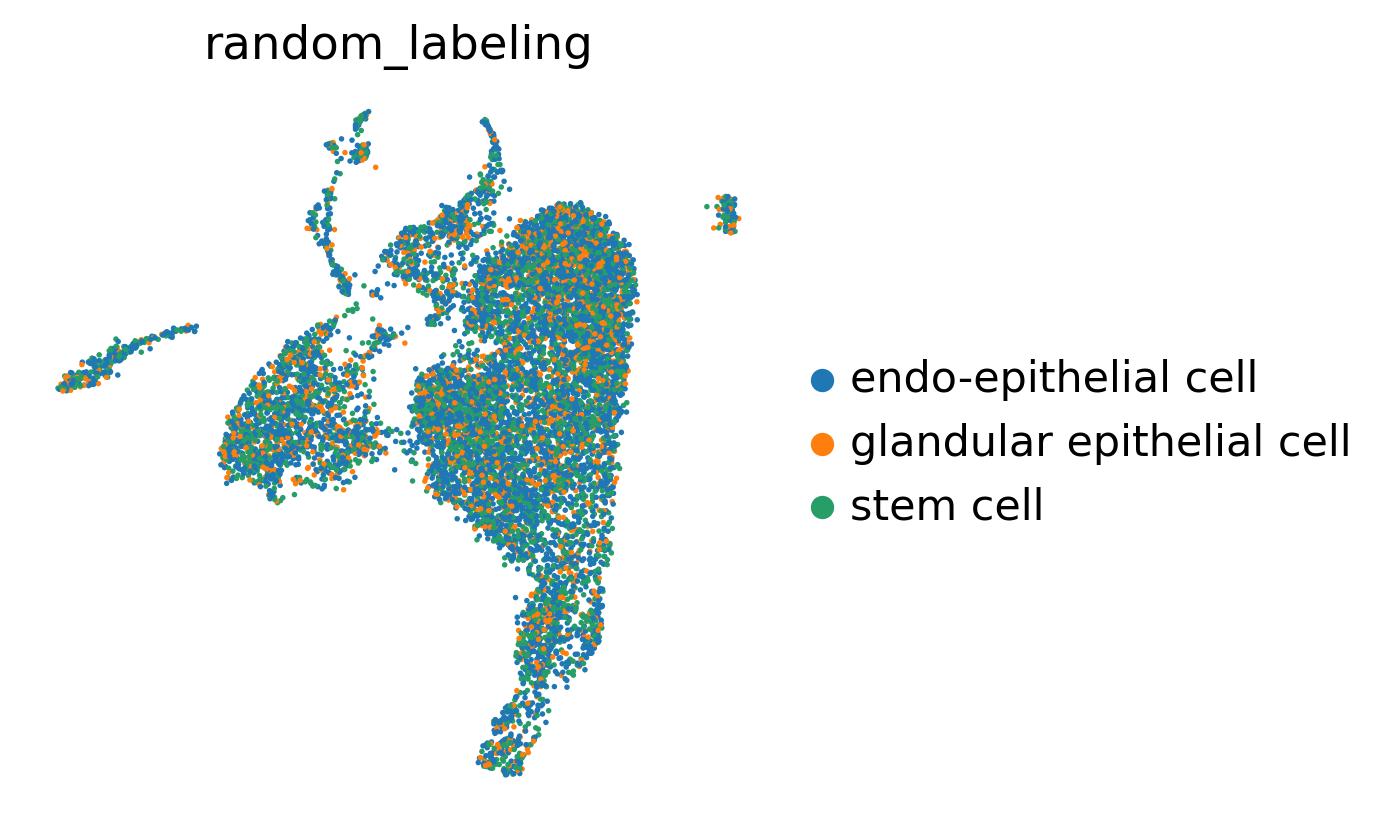

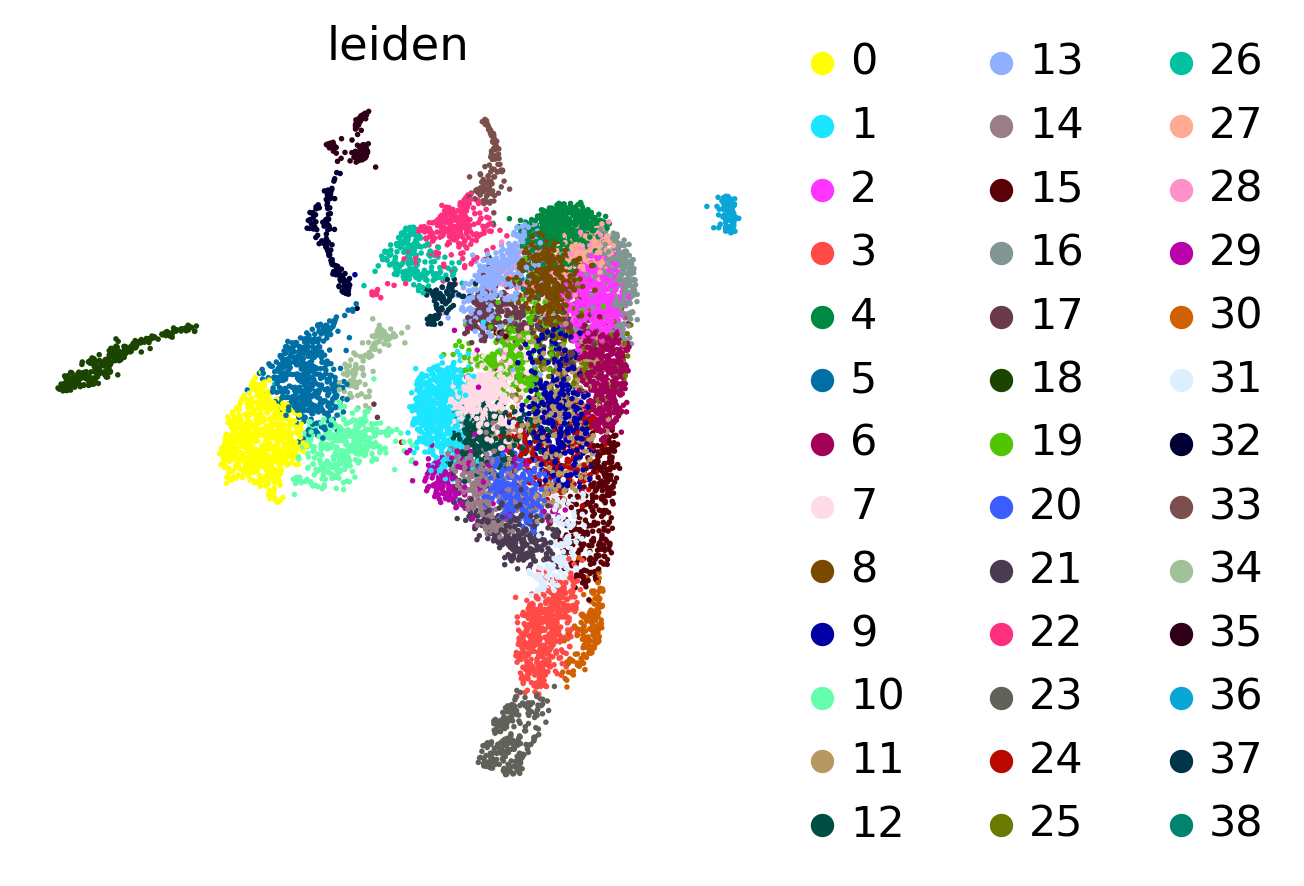

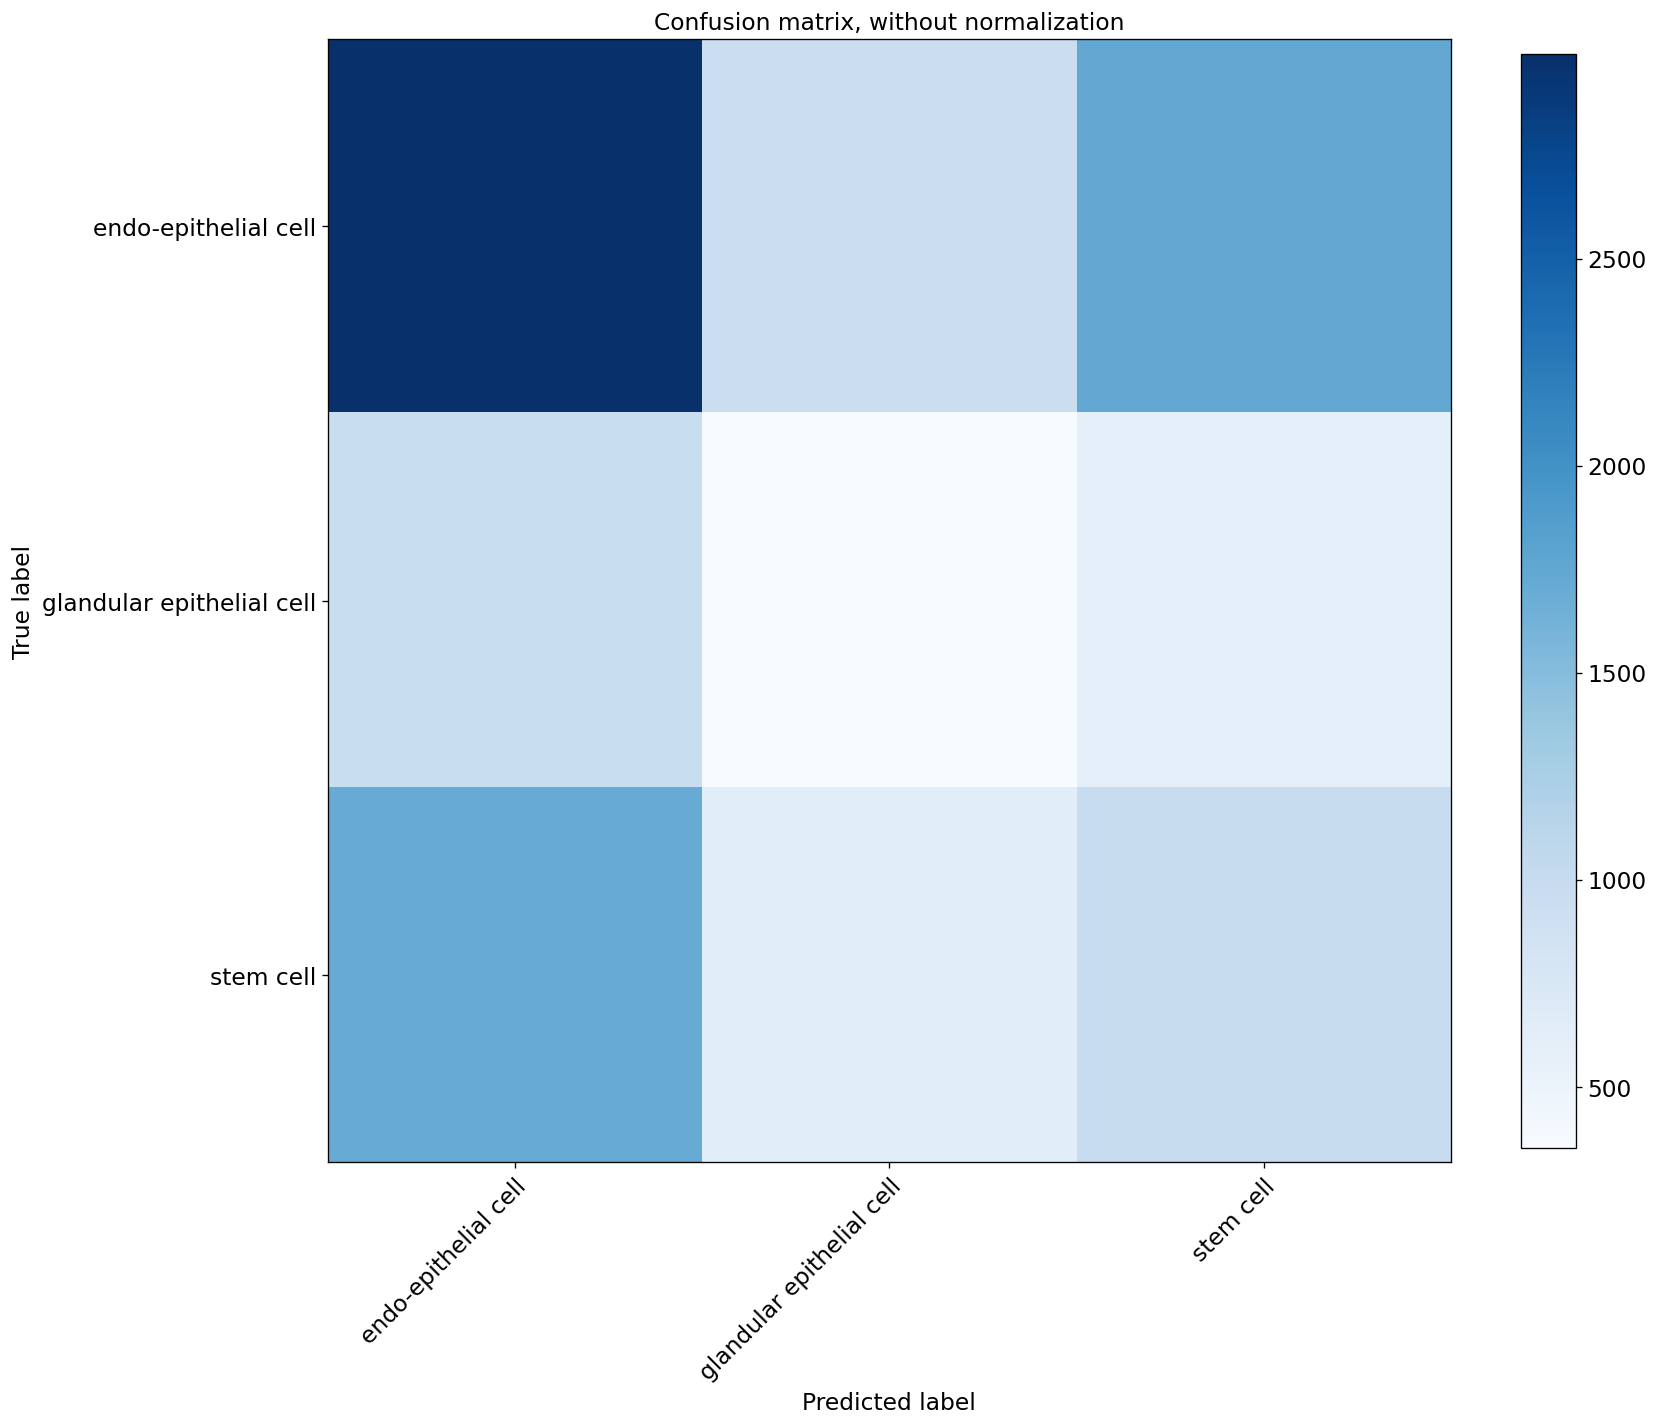

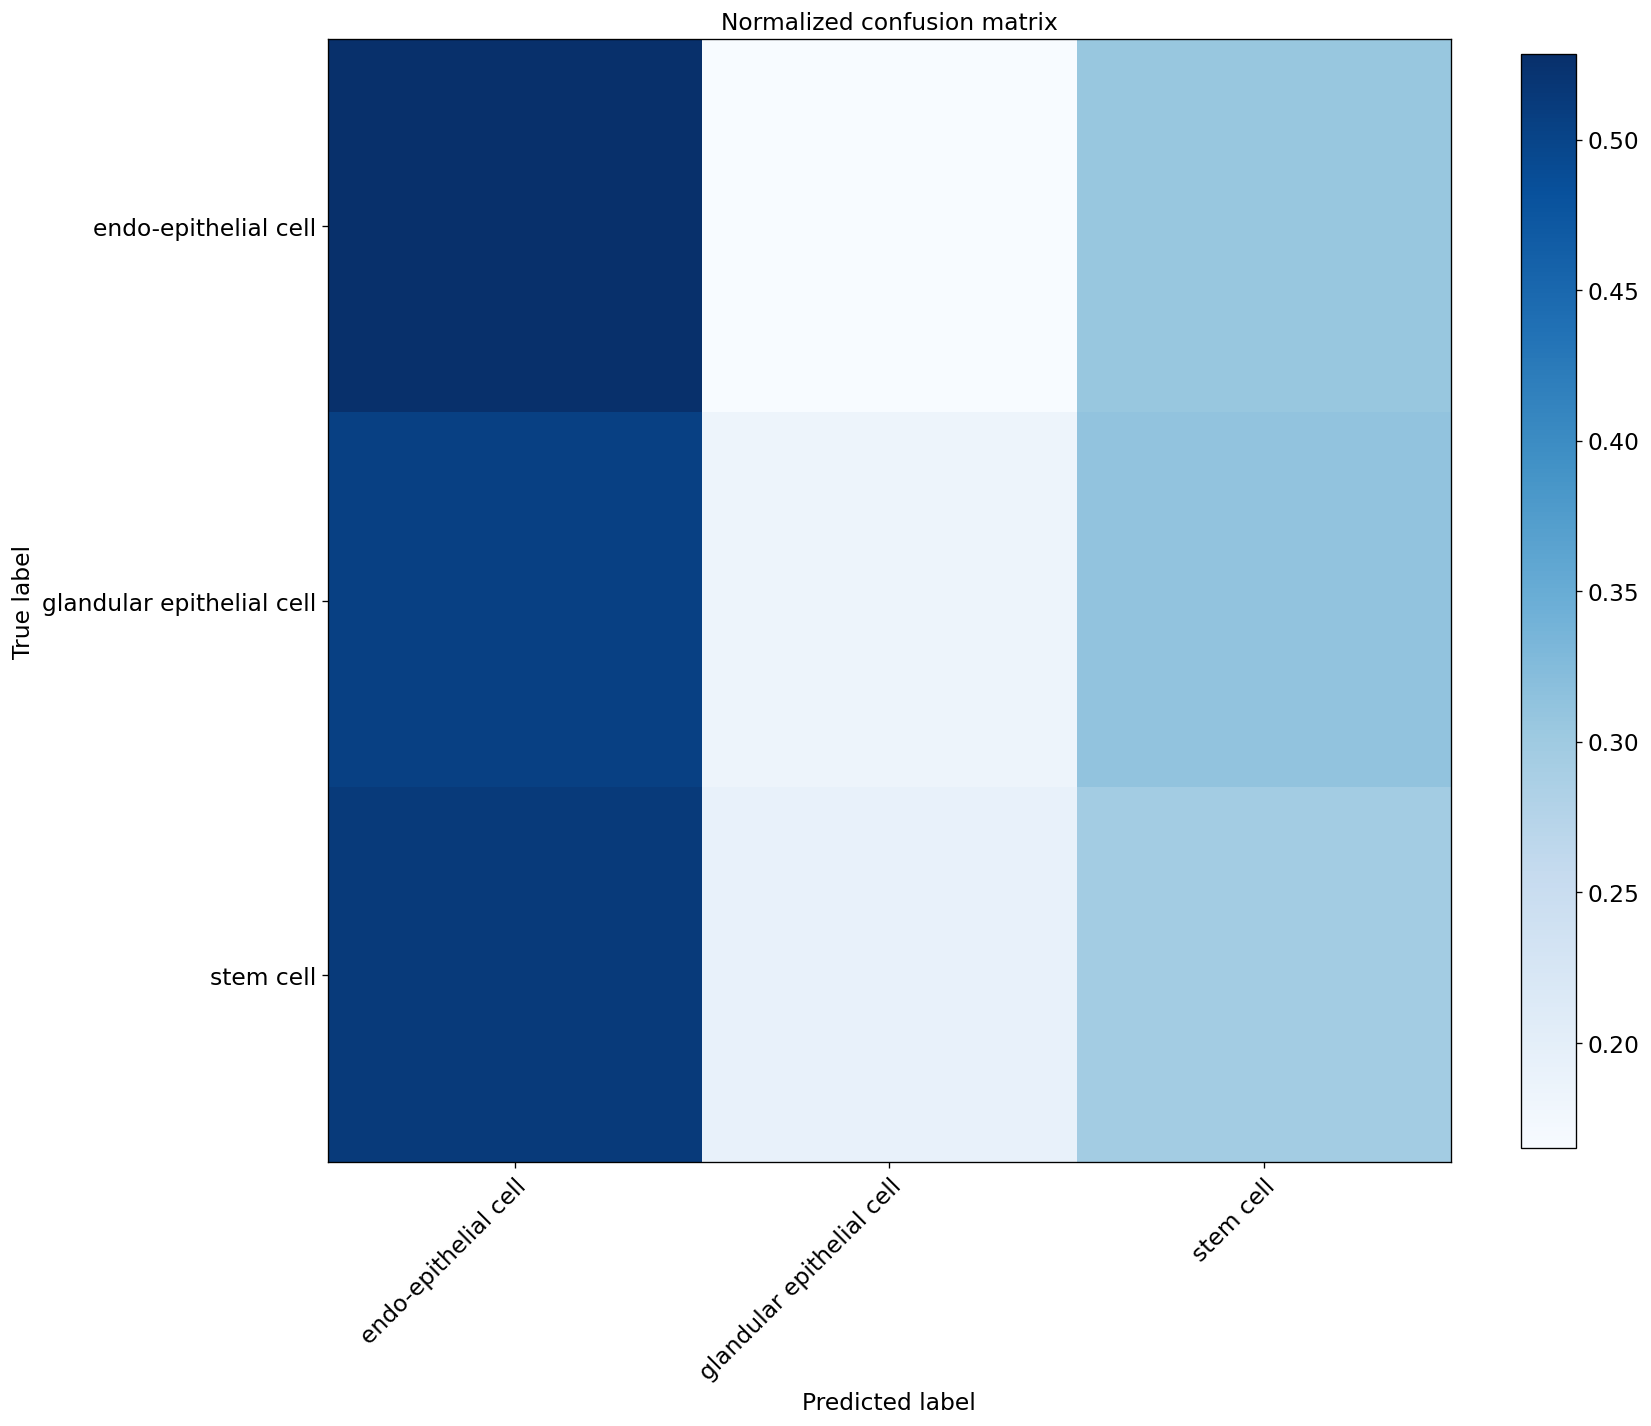

In [29]:
# Compare to random assignment
import random
random.seed(1)
adata_predicted.obs['random_labeling'] = list(adata_predicted.obs[celltype_test].sample(frac=1))

bc.tl.report(
    adata_pred=adata_predicted,
    celltype=celltype_test, 
    method="compare_to_random_" + method, 
    analysis_name=analysis_name,
    train_datasets = adata_trains,
    test_dataset = adata_orig,
    merge = merge,
    name_prediction="random_labeling",
    name_report="compare_to_random_auto_annot", 
    use_raw=use_raw,
    remove_nonshared=False, 
    clustering='leiden', 
    asymmetric_matrix=True, 
    delimiter='\t', 
    verbose=True)

In [30]:
try:
    from sinfo import sinfo
except ImportError:
    sinfo = lambda: print("sinfo not available")
sinfo()

-----
anndata             0.7.5
besca               2.4+57.g5ad53b2
pandas              1.2.2
pkg_resources       NA
plotly              4.14.3
scanpy              1.6.1
sinfo               0.3.1
sklearn             0.24.1
-----
IPython             7.20.0
jupyter_client      6.1.11
jupyter_core        4.7.1
notebook            6.2.0
-----
Python 3.7.9 | packaged by conda-forge | (default, Dec  9 2020, 21:08:20) [GCC 9.3.0]
Linux-3.10.0-693.11.6.el7.x86_64-x86_64-with-centos-7.4.1708-Core
24 logical CPU cores, x86_64
-----
Session information updated at 2021-07-18 08:58


### Convert to html

In [36]:
%%javascript

IPython.notebook.kernel.execute('nb_name = "' + IPython.notebook.notebook_name + '"')

<IPython.core.display.Javascript object>

In [37]:
nb_name = os.path.join(os.getcwd(), nb_name)

In [38]:
! jupyter nbconvert --to html {nb_name}

[NbConvertApp] Converting notebook /pstore/data/bioinfo/users/hatjek/devel/besca_publication_results/intestine/auto_annot/auto_annot_Haber2017_with_Smillie2019_dblabel_l2.ipynb to html
[NbConvertApp] Writing 8582324 bytes to /pstore/data/bioinfo/users/hatjek/devel/besca_publication_results/intestine/auto_annot/auto_annot_Haber2017_with_Smillie2019_dblabel_l2.html
